# Iris Flower Classification
**Oasis Infobyte SIP | Track: Data Science | Task 1**

**Objective:** Train machine learning classification models that identify the species of an iris flower (*Setosa*, *Versicolor* or *Virginica*) from its physical measurements, then compare the models and choose the best one.

**Tech stack:** Python, pandas, scikit-learn, matplotlib, seaborn, Jupyter Notebook

**Dataset:** Built into scikit-learn (`load_iris()`): 150 flowers, 4 measurements each, 50 flowers per species.

## 1. Import libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.feature_selection import f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2. Load the dataset

In [2]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()
# replace the numeric target (0, 1, 2) with the real species names
df["species"] = df["target"].map(dict(enumerate(iris.target_names)))
df = df.drop(columns="target")
df.columns = ["sepal_length", "sepal_width", "petal_length", "petal_width", "species"]
print(df.head())

   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa


## 3. Exploratory Data Analysis (EDA)
### 3.1 Shape, data types and null values

In [3]:
print("Shape (rows, columns):", df.shape)
print("\nData types:\n", df.dtypes)
print("\nNull values per column:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Shape (rows, columns): (150, 5)

Data types:
 sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species             str
dtype: object

Null values per column:
 sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Duplicate rows: 1


**Observation:** The data has 150 rows and 5 columns (4 numeric measurements in cm + the species label). There are **no missing values**, so no imputation is needed. One duplicate row exists; it is a genuine measurement that happens to repeat, so it is kept.

### 3.2 Descriptive statistics and class balance

In [4]:
print(df.describe().round(2))
print("\nSamples per species:\n", df["species"].value_counts())

       sepal_length  sepal_width  petal_length  petal_width
count        150.00       150.00        150.00       150.00
mean           5.84         3.06          3.76         1.20
std            0.83         0.44          1.77         0.76
min            4.30         2.00          1.00         0.10
25%            5.10         2.80          1.60         0.30
50%            5.80         3.00          4.35         1.30
75%            6.40         3.30          5.10         1.80
max            7.90         4.40          6.90         2.50

Samples per species:
 species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


**Observation:** The classes are perfectly balanced (50 each), so plain accuracy is a fair metric. Petal length and petal width vary a lot more across the dataset than sepal width does.

### 3.3 Visualisations
**Pairplot:** feature distributions and relationships, coloured by species.

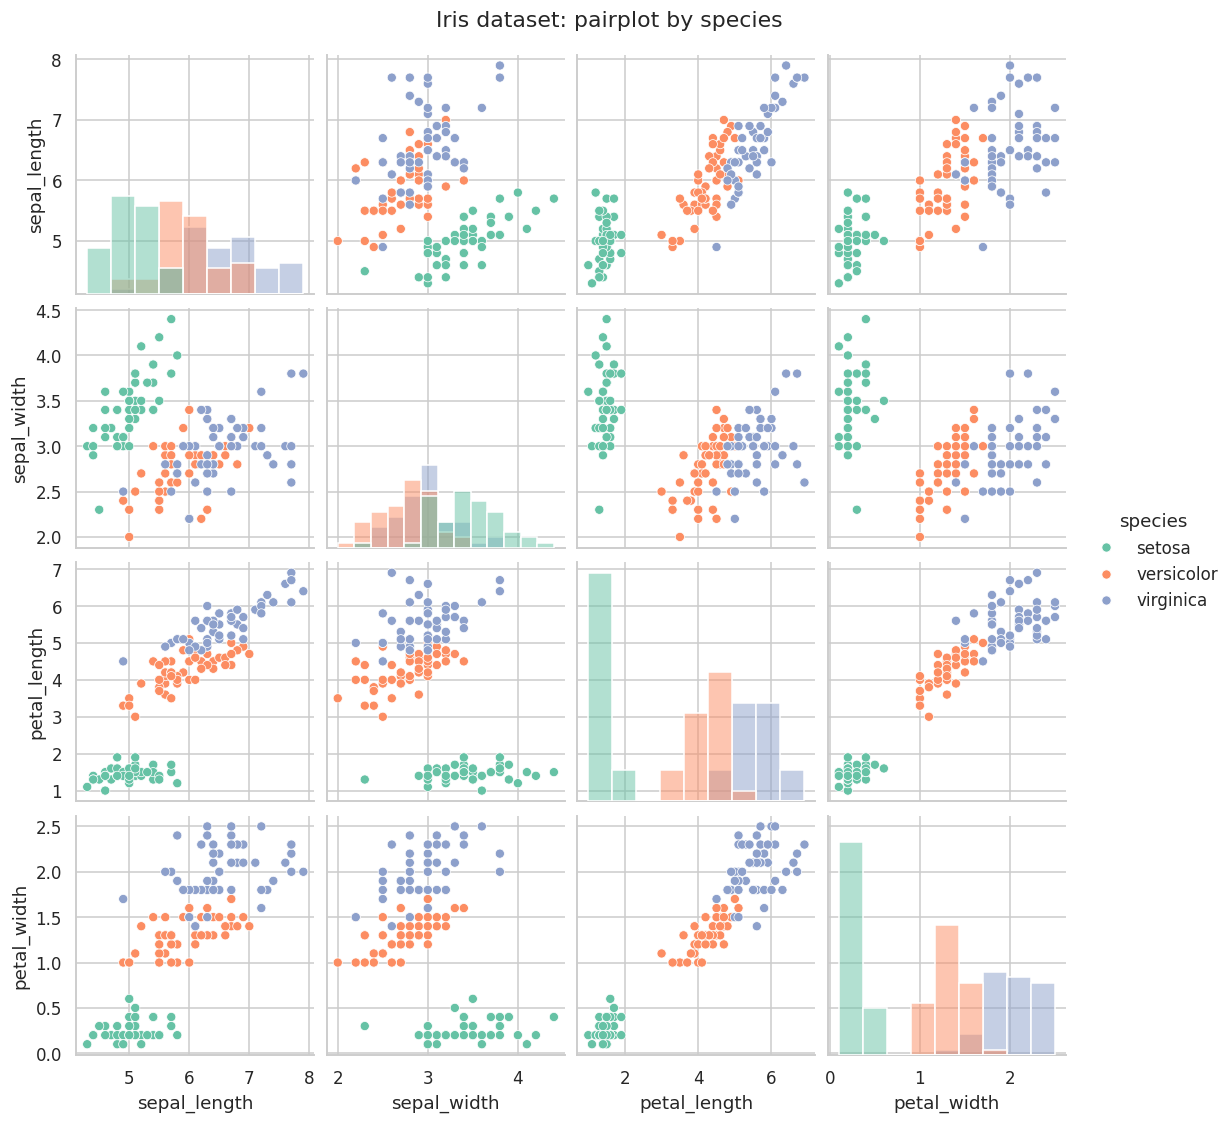

In [5]:
g = sns.pairplot(df, hue="species", palette="Set2", diag_kind="hist", corner=False)
g.fig.suptitle("Iris dataset: pairplot by species", y=1.02)
plt.show()

**Observation:** *Setosa* sits completely apart from the other two species in every petal plot. *Versicolor* and *Virginica* overlap a little, mainly in the sepal measurements, but they separate well on petal length and petal width.

**Box plots** for each feature, split by species.

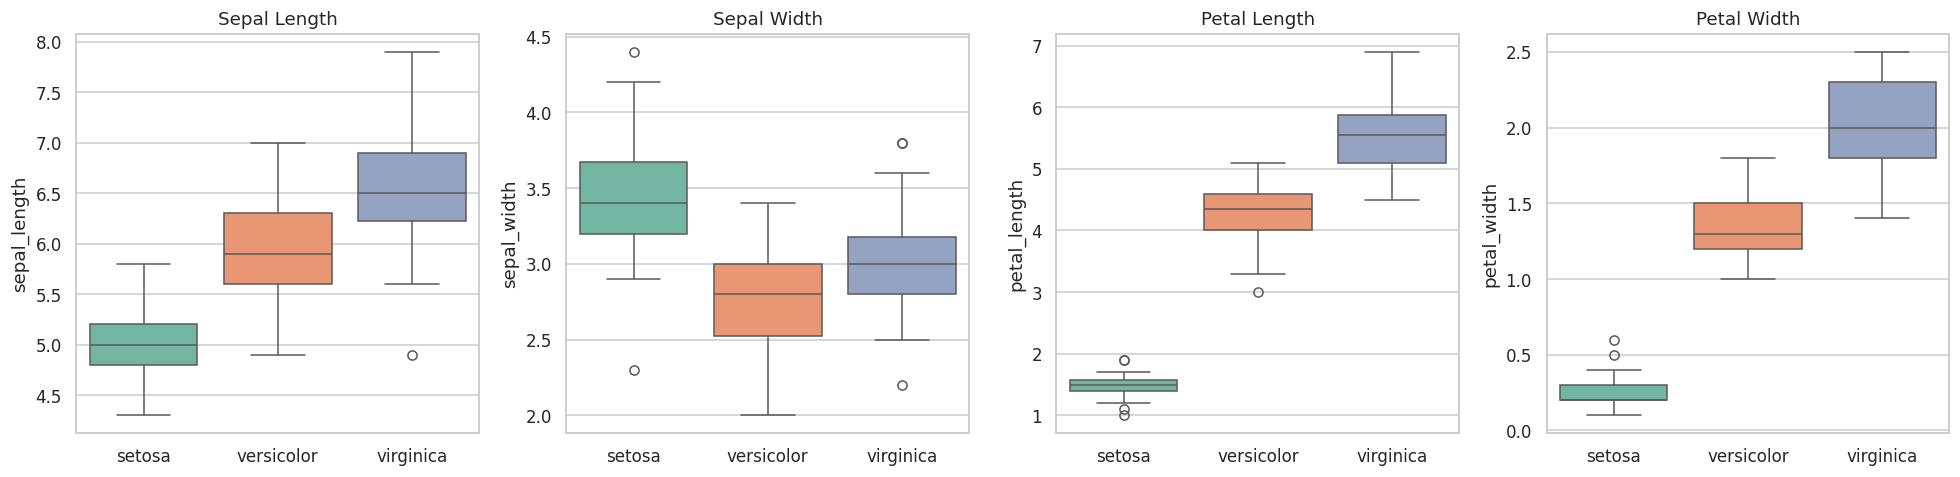

In [6]:
features = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, col in zip(axes, features):
    sns.boxplot(data=df, x="species", y=col, palette="Set2", ax=ax)
    ax.set_title(col.replace("_", " ").title())
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

**Observation:** In the petal length and petal width boxes the species overlap very little (Setosa is far below the others). In sepal width the three boxes overlap heavily, so it is the weakest feature. A few outliers exist (e.g. in sepal width) but they are real flowers, not errors.

**Correlation heatmap** of the four features.

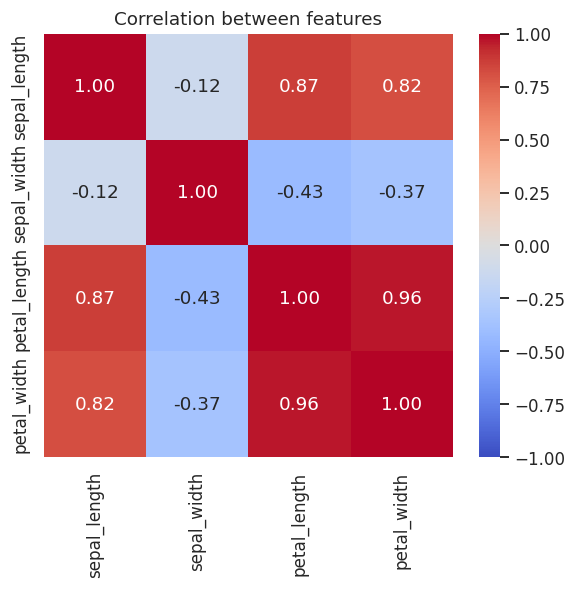

In [7]:
plt.figure(figsize=(6, 5))
sns.heatmap(df[features].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlation between features")
plt.show()

**Observation:** Petal length and petal width are very strongly correlated (about 0.96), and both are strongly correlated with sepal length. Sepal width is the odd one out (weak, negative correlation).

## 4. Feature selection: which features are most discriminative?
The ANOVA F-test measures how different the species averages are compared to the variation inside each species. A higher F-score means the feature separates the species better. A Random Forest gives a second opinion through feature importance.

     feature  ANOVA F-score      p-value  RF importance
petal_length         1180.2 2.856777e-91          0.455
 petal_width          960.0 4.169446e-85          0.417
sepal_length          119.3 1.669669e-31          0.107
 sepal_width           49.2 4.492017e-17          0.021


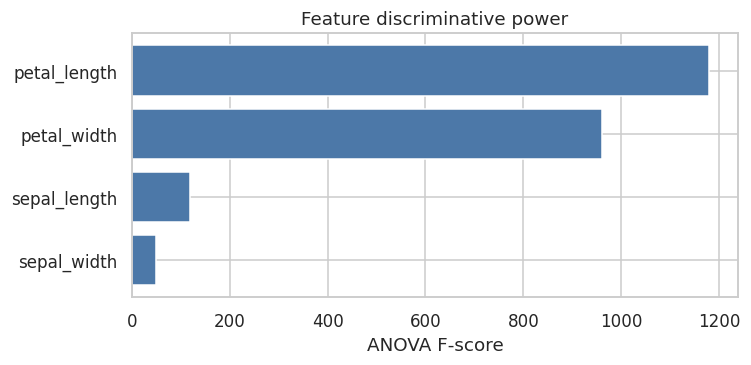

In [8]:
X = df[features]
y = df["species"]

f_scores, p_values = f_classif(X, y)
rf_tmp = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE).fit(X, y)

fs = pd.DataFrame({"feature": features, "ANOVA F-score": f_scores.round(1),
                   "p-value": p_values, "RF importance": rf_tmp.feature_importances_.round(3)})
print(fs.sort_values("ANOVA F-score", ascending=False).to_string(index=False))

fs_sorted = fs.sort_values("ANOVA F-score")
plt.figure(figsize=(7, 3.5))
plt.barh(fs_sorted["feature"], fs_sorted["ANOVA F-score"], color="#4c78a8")
plt.xlabel("ANOVA F-score")
plt.title("Feature discriminative power")
plt.tight_layout()
plt.show()

**Discussion:** **Petal length and petal width are the most discriminative features** (very high F-scores, and both dominate the Random Forest importance). Sepal length helps a little, and **sepal width is the least useful**. All four features are still kept because the dataset is tiny and removing sepal width would not make training any simpler in a meaningful way.

## 5. Train / test split (80 / 20)
`stratify=y` keeps the same species proportions in both sets.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
print("Training set:", X_train.shape, "| Test set:", X_test.shape)
print("\nTest set species counts:\n", y_test.value_counts())

Training set: (120, 4) | Test set: (30, 4)

Test set species counts:
 species
setosa        10
virginica     10
versicolor    10
Name: count, dtype: int64


## 6. Train the models
Four different classifiers are trained. Logistic Regression and KNN are distance/scale-sensitive, so they are wrapped in a pipeline with `StandardScaler`. Tree-based models do not need scaling.

In [10]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=500, random_state=RANDOM_STATE)),
    "K-Nearest Neighbours": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Decision Tree": DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
}

for name, model in models.items():
    model.fit(X_train, y_train)
print("All", len(models), "models trained.")

All 4 models trained.


## 7. Evaluate each model
For every model: accuracy, confusion matrix and classification report (precision, recall, F1) on the held-out test set.

Logistic Regression | Test accuracy: 0.9333
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.900     0.900     0.900        10
   virginica      0.900     0.900     0.900        10

    accuracy                          0.933        30
   macro avg      0.933     0.933     0.933        30
weighted avg      0.933     0.933     0.933        30

K-Nearest Neighbours | Test accuracy: 0.9333
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.833     1.000     0.909        10
   virginica      1.000     0.800     0.889        10

    accuracy                          0.933        30
   macro avg      0.944     0.933     0.933        30
weighted avg      0.944     0.933     0.933        30

Decision Tree | Test accuracy: 0.9667
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  

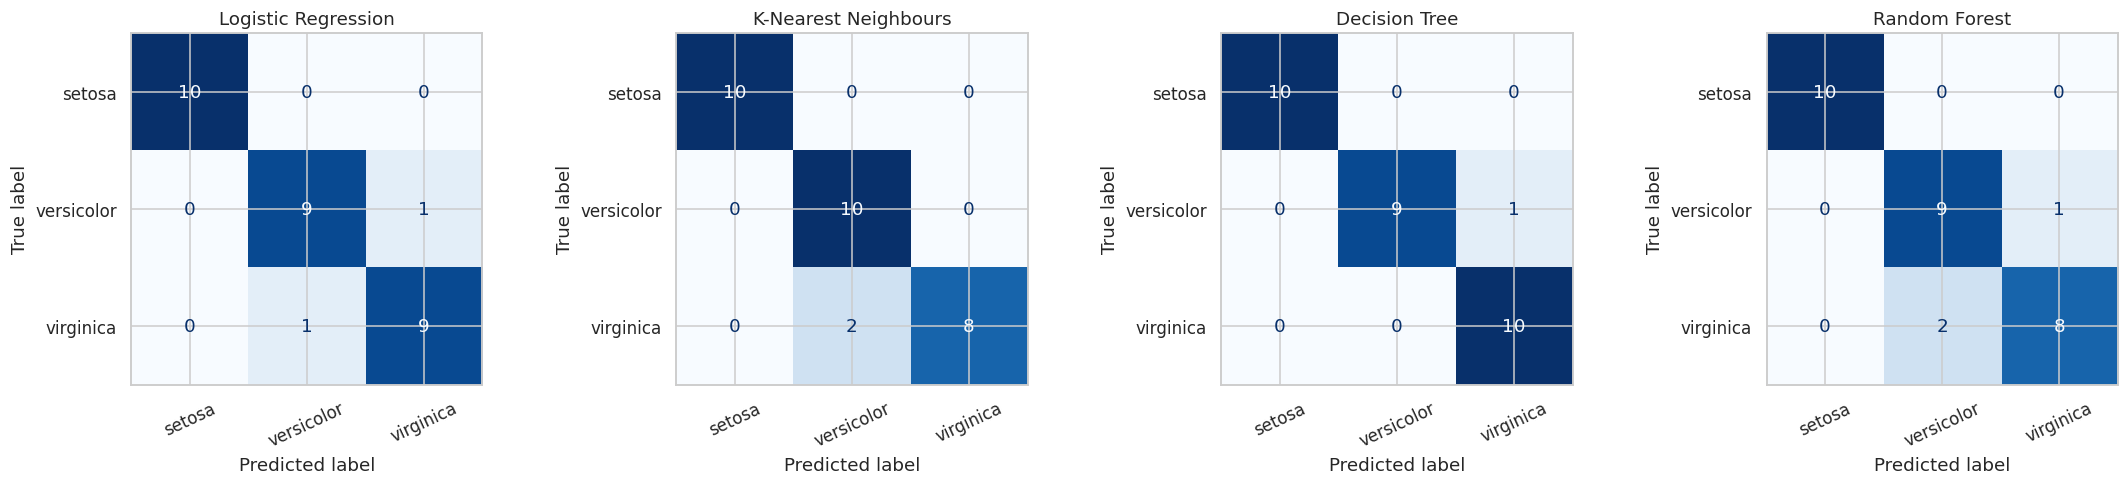

In [11]:
results = {}
labels = list(iris.target_names)

for name, model in models.items():
    pred = model.predict(X_test)
    acc = accuracy_score(y_test, pred)
    results[name] = acc
    print("=" * 60)
    print(name, "| Test accuracy: %.4f" % acc)
    print("=" * 60)
    print(classification_report(y_test, pred, target_names=labels, digits=3))

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, model.predict(X_test), labels=labels),
                           display_labels=labels).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
    ax.set_xticklabels(labels, rotation=25)
plt.tight_layout()
plt.show()

**Why also cross-validate?** The test set has only 30 flowers, so one mistake changes accuracy by about 3.3%. To make the comparison more reliable, each model is also scored with **stratified 5-fold cross-validation on the whole dataset** (every flower is used for testing exactly once).

               Model  Test accuracy (20% split)  5-fold CV mean  5-fold CV std
K-Nearest Neighbours                     0.9333          0.9733         0.0249
       Random Forest                     0.9000          0.9600         0.0389
       Decision Tree                     0.9667          0.9600         0.0249
 Logistic Regression                     0.9333          0.9533         0.0452


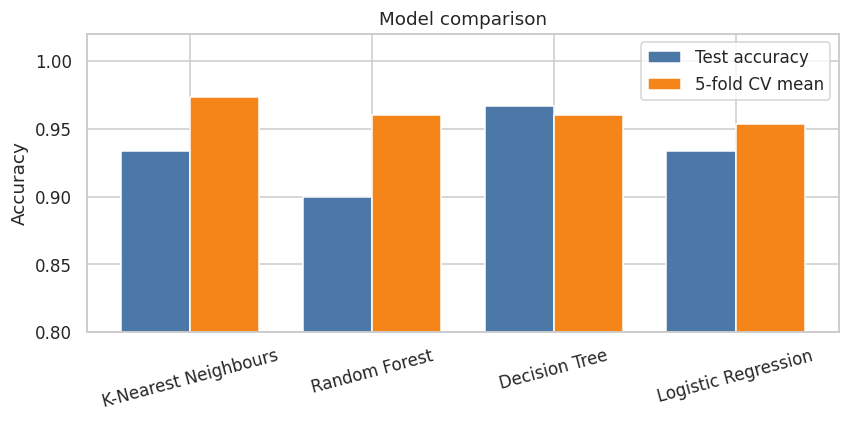

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
    rows.append([name, results[name], scores.mean(), scores.std()])

summary = pd.DataFrame(rows, columns=["Model", "Test accuracy (20% split)", "5-fold CV mean", "5-fold CV std"])
summary = summary.sort_values("5-fold CV mean", ascending=False).reset_index(drop=True)
print(summary.round(4).to_string(index=False))

plt.figure(figsize=(8, 4))
x = np.arange(len(summary)); w = 0.38
plt.bar(x - w/2, summary["Test accuracy (20% split)"], w, label="Test accuracy", color="#4c78a8")
plt.bar(x + w/2, summary["5-fold CV mean"], w, label="5-fold CV mean", color="#f58518")
plt.xticks(x, summary["Model"], rotation=15)
plt.ylim(0.8, 1.02); plt.ylabel("Accuracy"); plt.legend()
plt.title("Model comparison")
plt.tight_layout()
plt.show()

## 8. Conclusion: which model is the best?

| Model | Test accuracy (30 flowers) | 5-fold CV mean (150 flowers) |
|---|---|---|
| K-Nearest Neighbours | 93.3% | **97.3%** |
| Random Forest | 90.0% | 96.0% |
| Decision Tree | **96.7%** | 96.0% |
| Logistic Regression | 93.3% | 95.3% |

**What the results show**
- All four models score between 90% and 97%. *Setosa* was classified perfectly by every model; **every mistake was a Versicolor / Virginica mix-up**, exactly the overlap seen in the pairplot.
- On the single 80/20 split the Decision Tree looks best (96.7%) and the Random Forest worst (90.0%). But the test set has only 30 flowers, so one flower is worth 3.3 points. That ranking is mostly luck of the split.
- Under 5-fold cross-validation, where all 150 flowers are tested, **K-Nearest Neighbours is highest at 97.3%** with a small spread between folds (std about 2.5%).

**Declared best model: K-Nearest Neighbours (with feature scaling).** It has the highest cross-validated accuracy, which is the more reliable measure here, it matched the best models on the test split (93.3% = Logistic Regression), and it is simple and has no complicated training.

**Honest caveat:** the gap between the models (about 1-2 points) is smaller than the fold-to-fold variation, so all four are good choices for this dataset. If explaining the decision matters more than the last percent of accuracy, the Decision Tree is the easiest to explain. The Iris dataset is small and clean, so these scores will not carry over to messy real-world data.


## 9. Predicting a new flower (demo)
Using the best model to classify a flower the model has never seen.

In [13]:
best_name = summary.loc[0, "Model"]
best_model = models[best_name]

new_flower = pd.DataFrame([[5.9, 3.0, 5.1, 1.8]], columns=features)  # sepal L, sepal W, petal L, petal W (cm)
print("Best model:", best_name)
print("Predicted species for", new_flower.values.tolist()[0], "->", best_model.predict(new_flower)[0])
proba = getattr(best_model, "predict_proba", None)
if proba:
    for cls, pr in zip(best_model.classes_, proba(new_flower)[0]):
        print("  P(%s) = %.2f" % (cls, pr))

Best model: K-Nearest Neighbours
Predicted species for [5.9, 3.0, 5.1, 1.8] -> virginica
  P(setosa) = 0.00
  P(versicolor) = 0.40
  P(virginica) = 0.60
